In [3]:
import os
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [4]:
# ==============================================================================
# 1. KHAI BÁO CÁC HÀM Bổ TRỢ (HELPERS)
# ==============================================================================
def check_dataframe(df, show_head=True):
    """Kiểm tra tổng quan chất lượng dữ liệu DataFrame."""
    print("=" * 60)
    print("1. METADATA CỦA DỮ LIỆU (df.info())")
    print("=" * 60)
    df.info()
    print("\n")

    print("=" * 60)
    print("2. KIỂM TRA DỮ LIỆU TRÙNG LẶP")
    print("=" * 60)
    dup_count = df.duplicated().sum()
    dup_ratio = (dup_count / len(df)) * 100 if len(df) > 0 else 0
    print(f"- Số dòng bị trùng lặp: {dup_count:,} ({dup_ratio:.2f}%)")
    print("\n")

    print("=" * 60)
    print("3. KIỂM TRA DỮ LIỆU TRỐNG (MISSING VALUES)")
    print("=" * 60)
    null_count = df.isna().sum()
    null_ratio = (df.isna().sum() / len(df)) * 100 if len(df) > 0 else 0

    missing_df = pd.DataFrame(
        {
            "Kiểu dữ liệu": df.dtypes,
            "Số lượng trống": null_count,
            "Tỷ lệ trống (%)": null_ratio.round(2),
        }
    )

    missing_only = missing_df[missing_df["Số lượng trống"] > 0]
    if not missing_only.empty:
        print(missing_only.to_string())
    else:
        print("-> Không có dữ liệu trống trong bất kỳ cột nào.")
    print("\n")

    print("=" * 60)
    print("4. THỐNG KÊ MÔ TẢ DỮ LIỆU DẠNG SỐ (df.describe().T)")
    print("=" * 60)
    num_cols = df.select_dtypes(include=["number"]).columns
    if len(num_cols) > 0:
        print(df.describe().T.round(2).to_string())
    else:
        print("-> Không có cột dữ liệu dạng số trong DataFrame.")
    print("\n")

    if show_head:
        print("=" * 60)
        print("5. XEM TRƯỚC 5 DÒNG ĐẦU TIÊN (df.head())")
        print("=" * 60)
        print(df.head().to_string())
        print("\n")

In [5]:
def plot_pareto(
    df: pd.DataFrame,
    category_col: str,
    value_col: str,
    threshold: float = 0.80,
    title: str = None,
    figsize: tuple = (12, 6),
):
    """Vẽ biểu đồ Pareto linh hoạt cho bất kỳ tập dữ liệu nào."""
    df_plot = df.copy()

    # Gom nhóm và sắp xếp giảm dần theo giá trị
    df_plot = (
        df_plot.groupby(category_col)[value_col]
        .sum()
        .reset_index()
        .sort_values(by=value_col, ascending=False)
    )

    # Tính % tích lũy
    total_val = df_plot[value_col].sum()
    df_plot["pct_cum"] = df_plot[value_col].cumsum() / total_val

    # Vẽ biểu đồ
    fig, ax1 = plt.subplots(figsize=figsize)

    colors = [
        "#FF7F0E" if pct <= threshold else "#A9A9A9"
        for pct in df_plot["pct_cum"]
    ]

    if df_plot["pct_cum"].iloc[0] > threshold:
        colors[0] = "#FF7F0E"

    bars = ax1.bar(
        df_plot[category_col],
        df_plot[value_col],
        color=colors,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.85,
    )
    ax1.set_xlabel(category_col, fontsize=12, fontweight="bold", labelpad=10)
    ax1.set_ylabel(value_col, fontsize=12, color="black", fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.3)

    plt.setp(
        ax1.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"
    )

    # Trục tích lũy Y2
    ax2 = ax1.twinx()
    ax2.plot(
        df_plot[category_col],
        df_plot["pct_cum"] * 100,
        color="#1F77B4",
        marker="o",
        linewidth=2,
        markersize=6,
        label="Tích lũy (%)",
    )
    ax2.set_ylabel(
        "Tỷ lệ tích lũy (%)", fontsize=12, color="#1F77B4", fontweight="bold"
    )
    ax2.set_ylim(0, 105)

    thresh_pct = int(threshold * 100)
    ax2.axhline(
        y=thresh_pct,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Ngưỡng {thresh_pct}% (Pareto)",
    )

    if title is None:
        title = f"BIỂU ĐỒ PARETO - PHÂN TÍCH {value_col.upper()} THEO {category_col.upper()}"

    plt.title(title, fontsize=14, fontweight="bold", pad=15)

    legend_elements = [
        Patch(
            facecolor="#FF7F0E",
            label=f"Nhóm tạo {thresh_pct}% {value_col} (<= {thresh_pct}%)",
        ),
        Patch(facecolor="#A9A9A9", label=f"Nhóm còn lại (> {thresh_pct}%)"),
    ] + ax2.get_legend_handles_labels()[0]

    ax2.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.05, 1),
        borderaxespad=0.0,
    )

    plt.tight_layout()
    plt.show()

In [6]:
# ==============================================================================
# 2. ĐỌC DỮ LIỆU TỪ THƯ MỤC
# ==============================================================================
folder_path = "data"

In [7]:
df_orders = pd.read_csv(os.path.join(folder_path, "orders.csv"))
df_order_items = pd.read_csv(os.path.join(folder_path, "order_items.csv"))
df_order_item_refunds = pd.read_csv(
    os.path.join(folder_path, "order_item_refunds.csv")
)
df_products = pd.read_csv(os.path.join(folder_path, "products.csv"))
df_website_pageviews = pd.read_csv(
    os.path.join(folder_path, "website_pageviews.csv")
)
df_website_sessions = pd.read_csv(
    os.path.join(folder_path, "website_sessions.csv")
)

In [8]:
# Kiểm tra nhanh 1 bảng
check_dataframe(df_orders, show_head=False)
# Danh sách tất cả các DataFrame của bạn
all_dfs = {
    "df_orders": df_orders,
    "df_order_items": df_order_items,
    "df_order_item_refunds": df_order_item_refunds,
    "df_products": df_products,
    "df_website_sessions": df_website_sessions,
    "df_website_pageviews": df_website_pageviews,
}

1. METADATA CỦA DỮ LIỆU (df.info())
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  object 
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 2.0+ MB


2. KIỂM TRA DỮ LIỆU TRÙNG LẶP
- Số dòng bị trùng lặp: 0 (0.00%)


3. KIỂM TRA DỮ LIỆU TRỐNG (MISSING VALUES)
-> Không có dữ liệu trống trong bất kỳ cột nào.


4. THỐNG KÊ MÔ TẢ DỮ LIỆU DẠNG SỐ (df.describe().T)
                      count       mean        std    min        25%        50%        75%  

In [9]:
# Vòng lặp tự động tìm cột 'created_at' và ép kiểu sang datetime
for name, df in all_dfs.items():
    if "created_at" in df.columns:
        df["created_at"] = df["created_at"].astype("datetime64[ns]")
        print(f"✅ Đã chuyển đổi 'created_at' cho {name} thành công!")

✅ Đã chuyển đổi 'created_at' cho df_orders thành công!
✅ Đã chuyển đổi 'created_at' cho df_order_items thành công!
✅ Đã chuyển đổi 'created_at' cho df_order_item_refunds thành công!
✅ Đã chuyển đổi 'created_at' cho df_products thành công!
✅ Đã chuyển đổi 'created_at' cho df_website_sessions thành công!
✅ Đã chuyển đổi 'created_at' cho df_website_pageviews thành công!


In [10]:
# ==============================================================================
# 3. NHIỆM VỤ 1: PARETO SẢN PHẨM (TÌM GẤU "IN TIỀN")
# ==============================================================================
# Nối bảng: df_order_items -> df_products -> df_orders
df_items = df_order_items.merge(df_products, on="product_id", how="left")
df_items = df_items.merge(
    df_orders[["order_id", "created_at"]], on="order_id", how="left"
)

In [11]:
# Tính tổng doanh thu & lợi nhuận
product_sales = (
    df_items.groupby("product_name")
    .agg(
        total_revenue=("price_usd", "sum"),
        total_cogs=("cogs_usd", "sum"),
        total_sold=("order_item_id", "count"),
    )
    .reset_index()
)

In [12]:
product_sales["total_profit"] = (
    product_sales["total_revenue"] - product_sales["total_cogs"]
)
product_sales = product_sales.sort_values(
    by="total_revenue", ascending=False
).reset_index(drop=True)

In [13]:
# Tính % tích lũy
product_sales["cum_revenue"] = product_sales["total_revenue"].cumsum()
product_sales["cum_pct"] = (
    product_sales["cum_revenue"] / product_sales["total_revenue"].sum()
)

In [14]:
print("=" * 60)
print("=== BẢNG THỐNG KÊ PARETO SẢN PHẨM ===")
print("=" * 60)
print(product_sales[["product_name", "total_revenue", "total_profit", "cum_pct"]])

=== BẢNG THỐNG KÊ PARETO SẢN PHẨM ===
                 product_name  total_revenue  total_profit   cum_pct
0      The Original Mr. Fuzzy     1211057.74      738893.0  0.624736
1       The Forever Love Bear      347702.04      217350.0  0.804102
2    The Birthday Sugar Panda      229260.15      157027.5  0.922368
3  The Hudson River Mini bear      150489.82      102869.0  1.000000


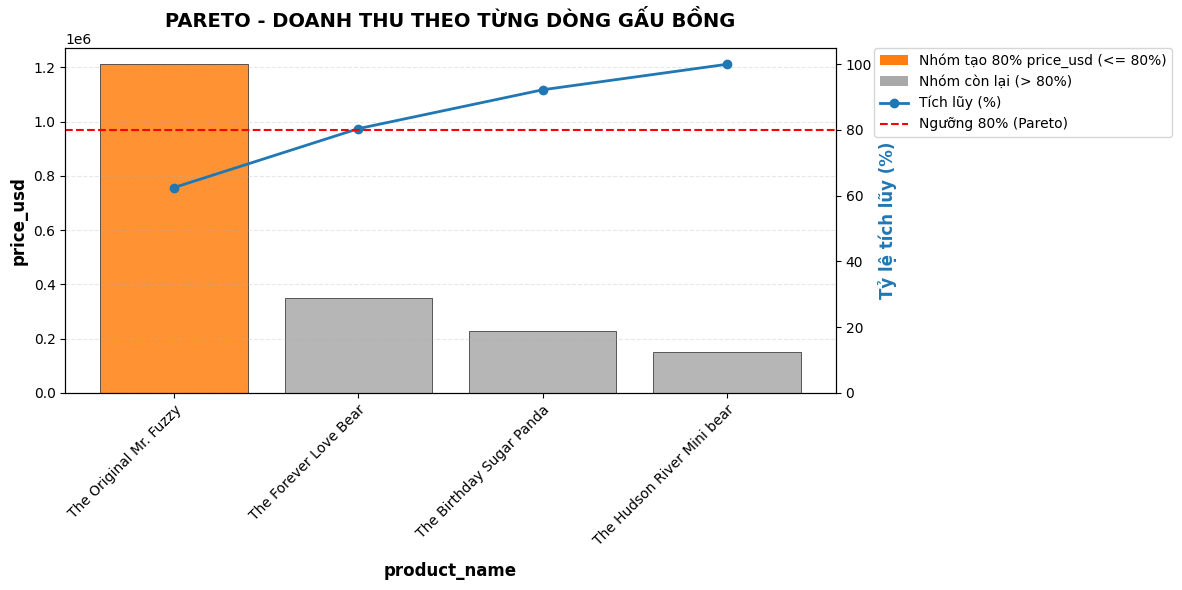

In [15]:
# Vẽ biểu đồ Pareto cho Sản phẩm
plot_pareto(
    df=df_items,
    category_col="product_name",
    value_col="price_usd",
    threshold=0.80,
    title="PARETO - DOANH THU THEO TỪNG DÒNG GẤU BỒNG",
)

In [16]:
# ==============================================================================
# 4. NHIỆM VỤ 2: PARETO MARKETING (TÌM KÊNH "HÁI RA TIỀN")
# ==============================================================================
# Nối bảng: df_orders -> df_website_sessions
df_mkt = df_orders.merge(df_website_sessions, on="website_session_id", how="left")

In [17]:
# Xử lý dữ liệu trống cho kênh Direct/Organic
df_mkt["utm_source"] = df_mkt["utm_source"].fillna("Direct / Organic")

In [18]:
# Tính toán chỉ số theo Kênh Marketing
mkt_sales = (
    df_mkt.groupby("utm_source")
    .agg(
        total_revenue=("price_usd", "sum"),
        total_orders=("order_id", "count"),
        avg_order_value=("price_usd", "mean"),
    )
    .reset_index()
)

In [19]:
mkt_sales = mkt_sales.sort_values(
    by="total_revenue", ascending=False
).reset_index(drop=True)

In [20]:
# Tính % tích lũy
mkt_sales["cum_revenue"] = mkt_sales["total_revenue"].cumsum()
mkt_sales["cum_pct"] = (
    mkt_sales["cum_revenue"] / mkt_sales["total_revenue"].sum()
)

In [21]:
print("\n" + "=" * 60)
print("=== BẢNG THỐNG KÊ PARETO MARKETING SOURCE ===")
print("=" * 60)
print(mkt_sales[["utm_source", "total_revenue", "total_orders", "cum_pct"]])


=== BẢNG THỐNG KÊ PARETO MARKETING SOURCE ===
         utm_source  total_revenue  total_orders   cum_pct
0           gsearch     1276144.89         21333  0.658312
1  Direct / Organic      371433.03          6118  0.849920
2           bsearch      268672.50          4519  0.988517
3        socialbook       22259.33           343  1.000000


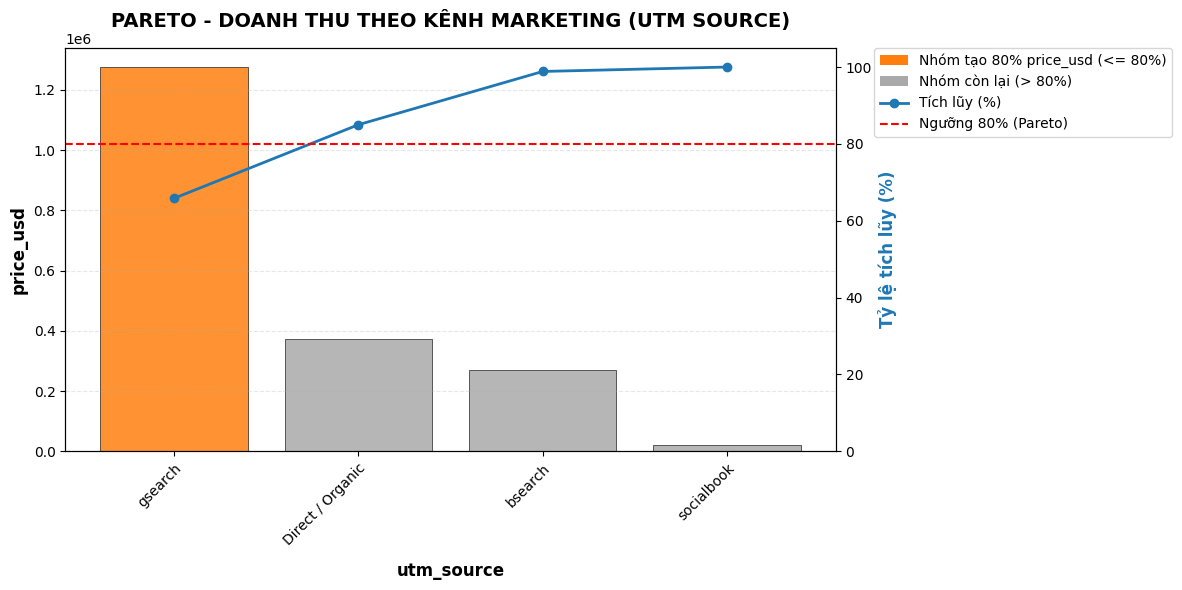

In [22]:
# Vẽ biểu đồ Pareto cho Marketing
plot_pareto(
    df=df_mkt,
    category_col="utm_source",
    value_col="price_usd",
    threshold=0.80,
    title="PARETO - DOANH THU THEO KÊNH MARKETING (UTM SOURCE)",
)

PHẦN 2: BÁO CÁO HIỆU QUẢ KÊNH MARKETING

1. Kênh MKT hái ra tiền của TeddyWorld là : gsearch || Số liệu : Đóng góp 1,276,144.89 USD doanh thu (chiếm 65% tổng doanh thu) với 21,333 đơn hàng.

2 . Tổng có 2 nguồn đóng góp vào 80% doanh thu là:

 1 . gsearch (65.83% tích lũy)  
 2. Direct / Organic (Truy cập trực tiếp / Tự nhiên - đóng góp thêm 19.16%, đưa tổng tích lũy lên 84.99%). 

3. Đề xuất giữ lại : 
1.gsearch (Google Search): Giữ lại 100% hoặc ưu tiên phần lớn ngân sách còn lại. Lý do: Kênh mang lại lượng khách hàng chuẩn xác và doanh thu lớn nhất (hơn 65%). \n
2.Direct / Organic: Đầu tư $0 chi phí quảng cáo trực tiếp (Tập trung SEO / Remarketing / CSKH).

Đề xuất cắt giảm / loại bỏ :
1. socialbook: Loại bỏ / Cắt giảm 100% ngân sách. 
Lý do: Chỉ mang về 22,259.33 USD (~1.15% tổng doanh thu) với 343 đơn hàng, hiệu quả chuyển đổi thấp so với chi phí duy trì.

2.bsearch (Bing Search): Cắt giảm 50% - 70% ngân sách.

Lý do: Chỉ đóng góp 13.86% doanh thu. Cần tối ưu lại từ khóa hoặc giảm bid thầu để dành ngân sách tối đa cho gsearch.

